In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

In [3]:
df = pd.read_csv("Downloads/emails.csv/emails.csv")

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


In [5]:
print(df.isnull().sum())
df.head()

Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [7]:
x = df.drop(["Email No.","Prediction"],axis=1)
y = df["Prediction"]

X_train,X_test,Y_train,Y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors = 5)
)
knn.fit(X_train,Y_train)
knn_pred = knn.predict(X_test)

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)
svm.fit(X_train,Y_train)
svm_pred = knn.predict(X_test)

In [8]:
from sklearn.metrics import f1_score,accuracy_score,recall_score,precision_score,classification_report,confusion_matrix

print("KNeighbors classification model\n")
print("Accuracy: ",accuracy_score(Y_test,knn_pred))
print("Recall: ",recall_score(Y_test,knn_pred))
print("precision: ",precision_score(Y_test,knn_pred))
print("f1 score: ",f1_score(Y_test,knn_pred))
print("Classification report: \n",classification_report(
    Y_test,knn_pred,target_names=["Spam","Not Spam"]
))

print("SVM classification model\n")
print("Accuracy: ",accuracy_score(Y_test,svm_pred))
print("Recall: ",recall_score(Y_test,svm_pred))
print("precision: ",precision_score(Y_test,svm_pred))
print("f1 score: ",f1_score(Y_test,svm_pred))
print("Classification report: \n",classification_report(
    Y_test,svm_pred,target_names=["Spam","Not Spam"]
))

KNeighbors classification model

Accuracy:  0.8454106280193237
Recall:  0.9527027027027027
precision:  0.6588785046728972
f1 score:  0.7790055248618785
Classification report: 
               precision    recall  f1-score   support

        Spam       0.98      0.80      0.88       739
    Not Spam       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035

SVM classification model

Accuracy:  0.8454106280193237
Recall:  0.9527027027027027
precision:  0.6588785046728972
f1 score:  0.7790055248618785
Classification report: 
               precision    recall  f1-score   support

        Spam       0.98      0.80      0.88       739
    Not Spam       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035


Text(50.722222222222214, 0.5, 'Actual')

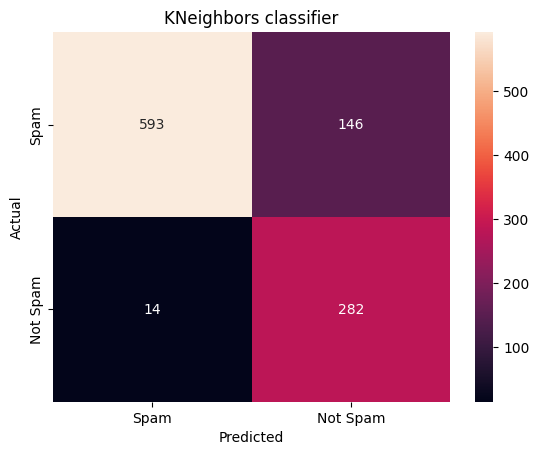

In [12]:
import seaborn as sns
cm = confusion_matrix(Y_test,knn_pred)

sns.heatmap(
    cm,annot=True,fmt="d",
    xticklabels = ["Spam","Not Spam"],
    yticklabels = ["Spam","Not Spam"]
)
plt.title("KNeighbors classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")




Text(50.722222222222214, 0.5, 'Actual')

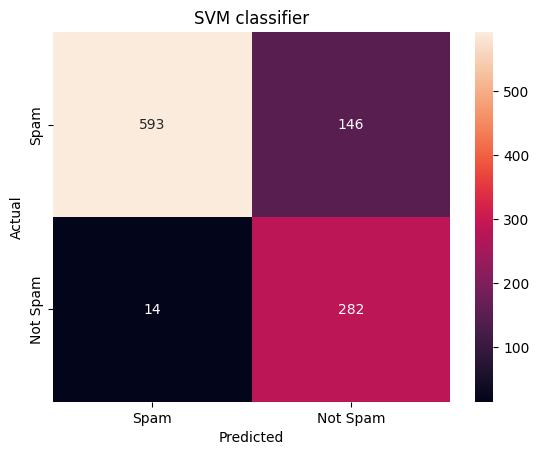

In [11]:
cm1 = confusion_matrix(Y_test,svm_pred)

sns.heatmap(
    cm1,annot=True,fmt="d",
    xticklabels = ["Spam","Not Spam"],
    yticklabels = ["Spam","Not Spam"]
)
plt.title("SVM classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")